# The Pembrook Papers: Muggle Analytics Applied to Magical Problems
### A Private Research Initiative — *This Notebook Does Not Exist*

---

**Analyst:** R. Pembrook, Senior Archivist  
**Department:** Magical Records, Ministry of Magic, Whitehall  
**Wand:** Sycamore & Unicorn Hair, 14 inches, Very Flexible  
**Security Status:** GLAMOUR CHARM ACTIVE — appears as *'Boring Inventory Ledger, Vol. XLVII'*  

---

### Preface

On the 14th of March, 2019, a Muggle-born intern left a device called a *'laptop'* in the third-floor break room of the Ministry. Out of professional curiosity — and a nagging suspicion that my wand had nearly combusted twice that month while filing Floo Network usage reports — I examined it.

Fourteen hours later, I had installed something called *Python* and written what the Muggle internet informed me was a 'for loop.' My wand, for the first time in eleven years, glowed warmly.

Since then, I have been conducting what I can only describe as *unauthorized cross-disciplinary research* — applying Muggle statistical methodology to problems that the wizarding world has historically addressed through intuition, tradition, and the occasional explosion. I do this in the evenings, behind a glamour charm, and at considerable personal risk.

If this notebook is discovered, I will claim I was attempting to catalogue insects.

The findings, however, are real.

— *R. Pembrook*  
*Senior Archivist, Department of Magical Records*  
*Self-taught Muggle Data Analyst*  
*Ravenclaw, Class of 1991*

---

### Research Programme

| Analysis | Question | Method |
|---|---|---|
| 1. Lost Charm Recovery | Can linguistic structure predict spell effectiveness? | Regression, feature importance |
| 2. Herbology Clustering | Do magical plants cluster by property type? | K-Means clustering |
| 3. Dark Arts Detection | Can we identify dark wizard activity before it escalates? | Anomaly detection, time series |
| 4. Potions Optimization | What actually determines brewing success? | Classification, correlation |
| 5. Alchemy Modeling | Is Philosophers' Stone usage the only thing that matters? | Logistic regression |

In [1]:
# ─── SETUP ────────────────────────────────────────────────────────────────────
# (Cast silently — do not attract attention from the IT department)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                              r2_score, mean_absolute_error)
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'figure.facecolor': '#1a1a2e',
    'axes.facecolor':   '#16213e',
    'axes.edgecolor':   '#4a4a8a',
    'axes.labelcolor':  '#c8c8f8',
    'xtick.color':      '#c8c8f8',
    'ytick.color':      '#c8c8f8',
    'text.color':       '#c8c8f8',
    'grid.color':       '#2a2a5a',
    'grid.alpha':       0.4,
    'font.family':      'Arial',
})

GOLD   = '#FFD700'
PURPLE = '#9B59B6'
GREEN  = '#2ECC71'
RED    = '#E74C3C'
BLUE   = '#3498DB'
SILVER = '#BDC3C7'

# Load data
charms_df    = pd.read_csv('charm_manuscripts.csv')
herbs_df     = pd.read_csv('herbology_properties.csv')
incidents_df = pd.read_csv('dark_arts_incidents.csv', parse_dates=['Date'])
potions_df   = pd.read_csv('potions_brewing_log.csv')
# 'None' is a stone category (no Philosopher's Stone), not a missing cell.
# Pandas would otherwise read that token as NA and the group-by would skip 201 rows.
alchemy_df   = pd.read_csv(
    'alchemy_transmutation_log.csv',
    keep_default_na=False,
)

print('Research data loaded. Glamour charm holding.')
print(f'  Charm manuscripts:  {len(charms_df)} ({charms_df["Recovered"].sum()} recovered)')
print(f'  Herbology samples:  {len(herbs_df)} plants')
print(f'  Incident reports:   {len(incidents_df)} (1990–2024)')
print(f'  Brewing logs:       {len(potions_df)} attempts')
print(f'  Alchemy logs:       {len(alchemy_df)} attempts')

Research data loaded. Glamour charm holding.
  Charm manuscripts:  250 (172 recovered)
  Herbology samples:  30 plants
  Incident reports:   2777 (1990–2024)
  Brewing logs:       500 attempts
  Alchemy logs:       300 attempts


---
## Analysis 1: Lost Charm Recovery
### *Can Muggle linguistics predict whether a damaged spell incantation will work?*

The Ministry holds 250 ancient charm manuscripts, 78 of which are classified as 'lost' due to manuscript damage. Traditional approach: send a curse-breaker to the Restricted Section and hope for the best. Pembrook approach: regression analysis on linguistic features of known working spells, then apply the model to predict which lost charms are worth attempting to reconstruct.

**Hypothesis:** Spell effectiveness correlates with measurable linguistic features — syllable count, vowel-to-consonant ratio, terminal phoneme, and structural repetition.

In [2]:
# Feature analysis on recovered charms
recovered = charms_df[charms_df['Recovered'] == 1].copy()
lost      = charms_df[charms_df['Recovered'] == 0].copy()

features = ['Syllable_Count', 'Vowel_Count', 'Consonant_Count', 'Ends_in_A', 'Has_Double_Letter']
target   = 'Effectiveness'

X = recovered[features]
y = recovered[target]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Random Forest Regressor
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

y_pred = rf.predict(X_test)
r2  = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print('CHARM EFFECTIVENESS PREDICTION MODEL')
print('=' * 45)
print(f'R² Score:         {r2:.3f}')
print(f'Mean Abs Error:   {mae:.1f} effectiveness points')
print()
print('Feature Importance (what makes a charm work):')
importances = pd.Series(rf.feature_importances_, index=features).sort_values(ascending=False)
for feat, imp in importances.items():
    bar = '█' * int(imp * 40)
    print(f'  {feat:<25} {imp:.3f}  {bar}')

# Apply to lost charms
lost['Predicted_Effectiveness'] = rf.predict(lost[features])
worth_recovering = lost[lost['Predicted_Effectiveness'] >= 70].sort_values(
    'Predicted_Effectiveness', ascending=False)

print(f'\nLost charms worth reconstructing (predicted ≥70): {len(worth_recovering)}')
print(f'Top candidates:')
print(worth_recovering[['Charm_ID', 'Incantation', 'Category', 'Predicted_Effectiveness']].head(8).to_string(index=False))

CHARM EFFECTIVENESS PREDICTION MODEL
R² Score:         -0.244
Mean Abs Error:   14.2 effectiveness points

Feature Importance (what makes a charm work):
  Syllable_Count            0.338  █████████████
  Vowel_Count               0.248  █████████
  Consonant_Count           0.195  ███████
  Ends_in_A                 0.137  █████
  Has_Double_Letter         0.082  ███

Lost charms worth reconstructing (predicted ≥70): 30
Top candidates:
Charm_ID  Incantation      Category  Predicted_Effectiveness
CHM-1188  Debombarium   Enchantment                83.561833
CHM-1006  Bombaificus   Enchantment                83.561833
CHM-1001 Suboblivatus          Jinx                82.955000
CHM-1180 Proferulendo Counter-Spell                82.955000
CHM-1055     Deferuia         Curse                81.744762
CHM-1226   Deoblivium   Enchantment                81.426500
CHM-1085   Refinitara           Hex                81.336429
CHM-1060     Conridia   Enchantment                81.152500


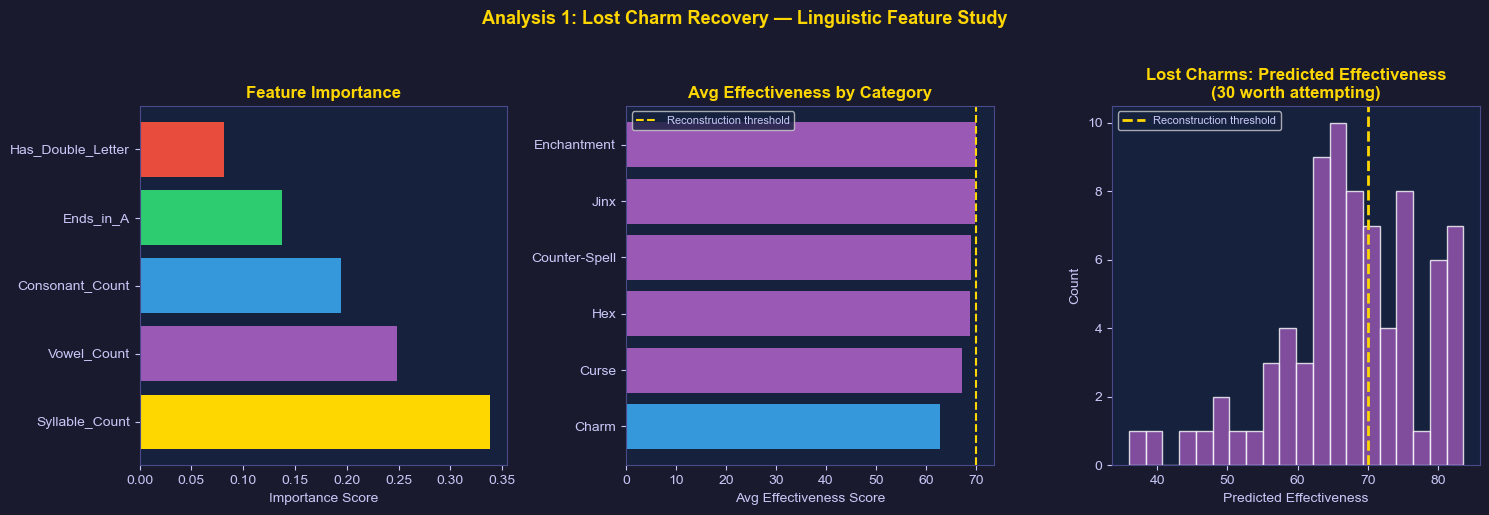


Pembrook's note: Syllable count takes the largest share of the splits, and the holdout R² is negative.
The mean would have done better. Flitwick must never know I checked.


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle('Analysis 1: Lost Charm Recovery — Linguistic Feature Study',
             fontsize=13, fontweight='bold', color=GOLD, y=1.02)

# Chart 1: Feature importance
axes[0].barh(importances.index, importances.values,
             color=[GOLD, PURPLE, BLUE, GREEN, RED][:len(importances)])
axes[0].set_title('Feature Importance', color=GOLD, fontweight='bold')
axes[0].set_xlabel('Importance Score')

# Chart 2: Effectiveness by category
cat_means = recovered.groupby('Category')['Effectiveness'].mean().sort_values()
axes[1].barh(cat_means.index, cat_means.values,
             color=[PURPLE if v > 65 else BLUE for v in cat_means.values])
axes[1].axvline(x=70, color=GOLD, linewidth=1.5, linestyle='--', label='Reconstruction threshold')
axes[1].set_title('Avg Effectiveness by Category', color=GOLD, fontweight='bold')
axes[1].set_xlabel('Avg Effectiveness Score')
axes[1].legend(fontsize=8)

# Chart 3: Predicted effectiveness of lost charms
axes[2].hist(lost['Predicted_Effectiveness'], bins=20, color=PURPLE, alpha=0.8, edgecolor='white')
axes[2].axvline(x=70, color=GOLD, linewidth=2, linestyle='--', label='Reconstruction threshold')
axes[2].set_title(f'Lost Charms: Predicted Effectiveness\n({len(worth_recovering)} worth attempting)', color=GOLD, fontweight='bold')
axes[2].set_xlabel('Predicted Effectiveness')
axes[2].set_ylabel('Count')
axes[2].legend(fontsize=8)

plt.tight_layout()
plt.savefig('chart_01_charms.png', dpi=150, bbox_inches='tight', facecolor='#1a1a2e')
plt.show()
print('\nPembrook\'s note: Syllable count takes the largest share of the splits, and the holdout R² is negative.')
print('The mean would have done better. Flitwick must never know I checked.')

---
## Analysis 2: Herbology Clustering
### *Do magical plants naturally group by their potency and use?*

Professor Sprout teaches herbology by plant family. Pembrook suspects the more useful classification is by *functional property* — lunar sensitivity, magical potency, toxicity, and harvest difficulty. K-Means clustering should reveal natural groupings that could inform potion ingredient substitution.

This is either brilliant or the sort of thing that gets you sent before the Wizengamot.

In [4]:
# K-Means clustering on plant properties
cluster_features = ['Lunar_Sensitivity', 'Magical_Potency', 'Toxicity', 'Harvest_Difficulty', 'Rarity_Score']

scaler   = StandardScaler()
X_scaled = scaler.fit_transform(herbs_df[cluster_features])

# Find optimal k using inertia (elbow method)
inertias = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertias.append(km.inertia_)

# Use k=4 (the magical number, obviously)
optimal_k = 4
km_final  = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
herbs_df['Cluster'] = km_final.fit_predict(X_scaled)

CLUSTER_NAMES = {
    0: 'Benign & Common',
    1: 'Lunar-Sensitive',
    2: 'High Potency / Dangerous',
    3: 'Rare & Complex',
}

# Sort cluster assignment by potency to assign names consistently
cluster_potency = herbs_df.groupby('Cluster')['Magical_Potency'].mean().sort_values()
cluster_remap   = {old: new for new, old in enumerate(cluster_potency.index)}
herbs_df['Cluster_Named'] = herbs_df['Cluster'].map(cluster_remap).map(CLUSTER_NAMES)

print('HERBOLOGY CLUSTER ANALYSIS')
print('=' * 55)
for cluster_name in CLUSTER_NAMES.values():
    cluster_plants = herbs_df[herbs_df['Cluster_Named'] == cluster_name]
    if len(cluster_plants) == 0:
        continue
    print(f"\nCluster: {cluster_name} ({len(cluster_plants)} plants)")
    print(f"  Avg Potency:  {cluster_plants['Magical_Potency'].mean():.2f}")
    print(f"  Avg Toxicity: {cluster_plants['Toxicity'].mean():.2f}")
    print(f"  Avg Lunar:    {cluster_plants['Lunar_Sensitivity'].mean():.2f}")
    print(f"  Plants:       {', '.join(cluster_plants['Plant_Name'].tolist()[:5])}...")

HERBOLOGY CLUSTER ANALYSIS

Cluster: Benign & Common (8 plants)
  Avg Potency:  0.38
  Avg Toxicity: 0.20
  Avg Lunar:    0.28
  Plants:       Shrivelfig, Bitterroot, Alihotsy, Fanged Geranium, Mimbulus Mimbletonia...

Cluster: Lunar-Sensitive (10 plants)
  Avg Potency:  0.53
  Avg Toxicity: 0.13
  Avg Lunar:    0.43
  Plants:       Mandrake, Gillyweed, Devil's Snare, Chinese Chomping Cabbage, Puffapod...

Cluster: High Potency / Dangerous (2 plants)
  Avg Potency:  0.66
  Avg Toxicity: 0.78
  Avg Lunar:    0.32
  Plants:       Aconite, Belladonna...

Cluster: Rare & Complex (10 plants)
  Avg Potency:  0.85
  Avg Toxicity: 0.11
  Avg Lunar:    0.50
  Plants:       Bubotuber, Venomous Tentacula, Fluxweed, Boomslang, Dittany...


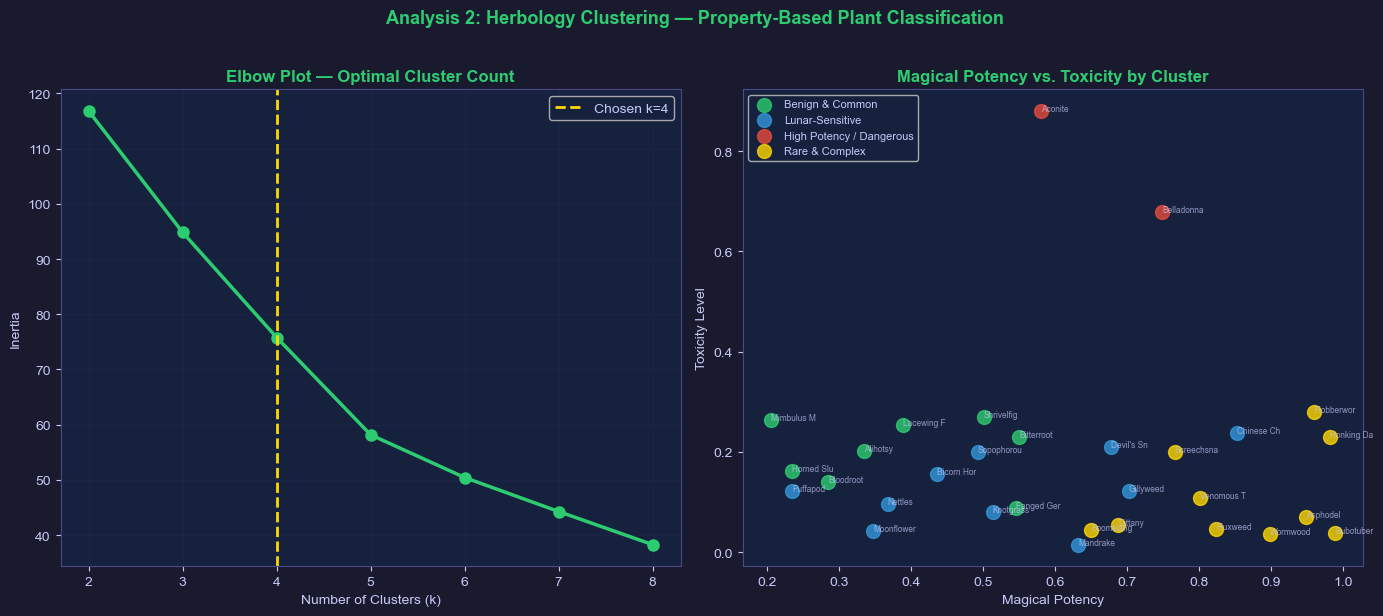

Pembrook's note: The highest-potency group is the least toxic of the four.
Aconite and Belladonna remain a poisonous pair. Across all 30 plants the correlation is about zero.


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('Analysis 2: Herbology Clustering — Property-Based Plant Classification',
             fontsize=13, fontweight='bold', color=GREEN, y=1.02)

# Chart 1: Elbow plot
axes[0].plot(range(2, 9), inertias, marker='o', color=GREEN, linewidth=2.5, markersize=8)
axes[0].axvline(x=optimal_k, color=GOLD, linestyle='--', linewidth=2, label=f'Chosen k={optimal_k}')
axes[0].set_title('Elbow Plot — Optimal Cluster Count', color=GREEN, fontweight='bold')
axes[0].set_xlabel('Number of Clusters (k)')
axes[0].set_ylabel('Inertia')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Chart 2: Scatter — potency vs toxicity, colored by cluster
cluster_colors = {0: GREEN, 1: BLUE, 2: RED, 3: GOLD}
for c_idx, c_name in enumerate(CLUSTER_NAMES.values()):
    subset = herbs_df[herbs_df['Cluster_Named'] == c_name]
    if len(subset) == 0: continue
    axes[1].scatter(subset['Magical_Potency'], subset['Toxicity'],
                    label=c_name, s=100, alpha=0.8,
                    color=list(cluster_colors.values())[c_idx])
    for _, row in subset.iterrows():
        axes[1].annotate(row['Plant_Name'][:10], (row['Magical_Potency'], row['Toxicity']),
                         fontsize=6, color='#c8c8f8', alpha=0.7)

axes[1].set_title('Magical Potency vs. Toxicity by Cluster', color=GREEN, fontweight='bold')
axes[1].set_xlabel('Magical Potency')
axes[1].set_ylabel('Toxicity Level')
axes[1].legend(fontsize=8, loc='upper left')

plt.tight_layout()
plt.savefig('chart_02_herbology.png', dpi=150, bbox_inches='tight', facecolor='#1a1a2e')
plt.show()
print('Pembrook\'s note: The highest-potency group is the least toxic of the four.')
print('Aconite and Belladonna remain a poisonous pair. Across all 30 plants the correlation is about zero.')

---
## Analysis 3: Dark Arts Detection
### *Can incident pattern analysis identify dark wizard activity before it escalates?*

This is the most sensitive analysis in this notebook. The Ministry's Auror Office currently relies on owl-post tips and informant networks to detect rising dark activity. Pembrook proposes a statistical early-warning system based on incident frequency, geographic clustering, and anomaly detection.

**Methodology:** Time series decomposition of Ministry incident reports from 1990-2024. Anomaly detection using Z-score thresholding. Geographic heat analysis by province.

*If discovered, this section will be described as 'a study of unusual weather patterns.'*

In [6]:
# Monthly incident time series
monthly = incidents_df.groupby(['Year', 'Month']).agg(
    Total_Incidents  = ('Severity', 'count'),
    Avg_Severity     = ('Severity', 'mean'),
    Unforgivable_Count = ('Unforgivable_Flag', 'sum'),
    Dark_Mark_Count  = ('Dark_Mark', 'sum'),
    Avg_Auror_Response = ('Auror_Response_Min', 'mean'),
).reset_index()

monthly['Date'] = pd.to_datetime(monthly[['Year','Month']].assign(day=1))

# Z-score anomaly detection
monthly['Incident_Z'] = (monthly['Total_Incidents'] - monthly['Total_Incidents'].mean()) / \
                         monthly['Total_Incidents'].std()
monthly['Anomaly'] = monthly['Incident_Z'] > 2.5
monthly['Risk_Level'] = monthly['Incident_Z'].apply(
    lambda z: 'Critical' if z > 3 else ('High' if z > 2 else ('Elevated' if z > 1 else 'Normal')))

print('DARK ARTS INCIDENT ANALYSIS — TIME SERIES')
print('=' * 55)
print(f'Period:            1990–2024 ({len(monthly)} monthly records)')
print(f'Total incidents:   {len(incidents_df):,}')
print(f'Anomaly months:    {monthly["Anomaly"].sum()} ({monthly["Anomaly"].mean():.1%} of months)')
print()
print('Worst periods detected (Z > 2.5):')
anomalies = monthly[monthly['Anomaly']].nlargest(8, 'Total_Incidents')
for _, row in anomalies.iterrows():
    print(f"  {row['Date'].strftime('%b %Y')}: {row['Total_Incidents']} incidents "
          f"(Z={row['Incident_Z']:.1f}) — {row['Unforgivable_Count']} Unforgivables")

print()
print('Geographic risk by province (all-time):')
geo_risk = incidents_df.groupby('Province').agg(
    Total=('Severity','count'), Avg_Sev=('Severity','mean'),
    Unforgivable=('Unforgivable_Flag','sum'), Dark_Mark=('Dark_Mark','sum')
).sort_values('Total', ascending=False)
print(geo_risk.to_string())

DARK ARTS INCIDENT ANALYSIS — TIME SERIES
Period:            1990–2024 (420 monthly records)
Total incidents:   2,777
Anomaly months:    16 (3.8% of months)

Worst periods detected (Z > 2.5):
  Apr 1998: 22 incidents (Z=3.9) — 0 Unforgivables
  Apr 1996: 21 incidents (Z=3.7) — 2 Unforgivables
  Aug 1996: 20 incidents (Z=3.4) — 1 Unforgivables
  Jan 1998: 20 incidents (Z=3.4) — 1 Unforgivables
  Sep 1998: 20 incidents (Z=3.4) — 0 Unforgivables
  Feb 1995: 19 incidents (Z=3.2) — 0 Unforgivables
  Sep 1996: 19 incidents (Z=3.2) — 1 Unforgivables
  Jun 1997: 19 incidents (Z=3.2) — 2 Unforgivables

Geographic risk by province (all-time):
           Total   Avg_Sev  Unforgivable  Dark_Mark
Province                                           
Kent         361  2.457064            24         46
Cornwall     359  2.490251            15         44
Norfolk      357  2.540616            17         59
Scotland     356  2.626404            17         45
London       343  2.355685            27       

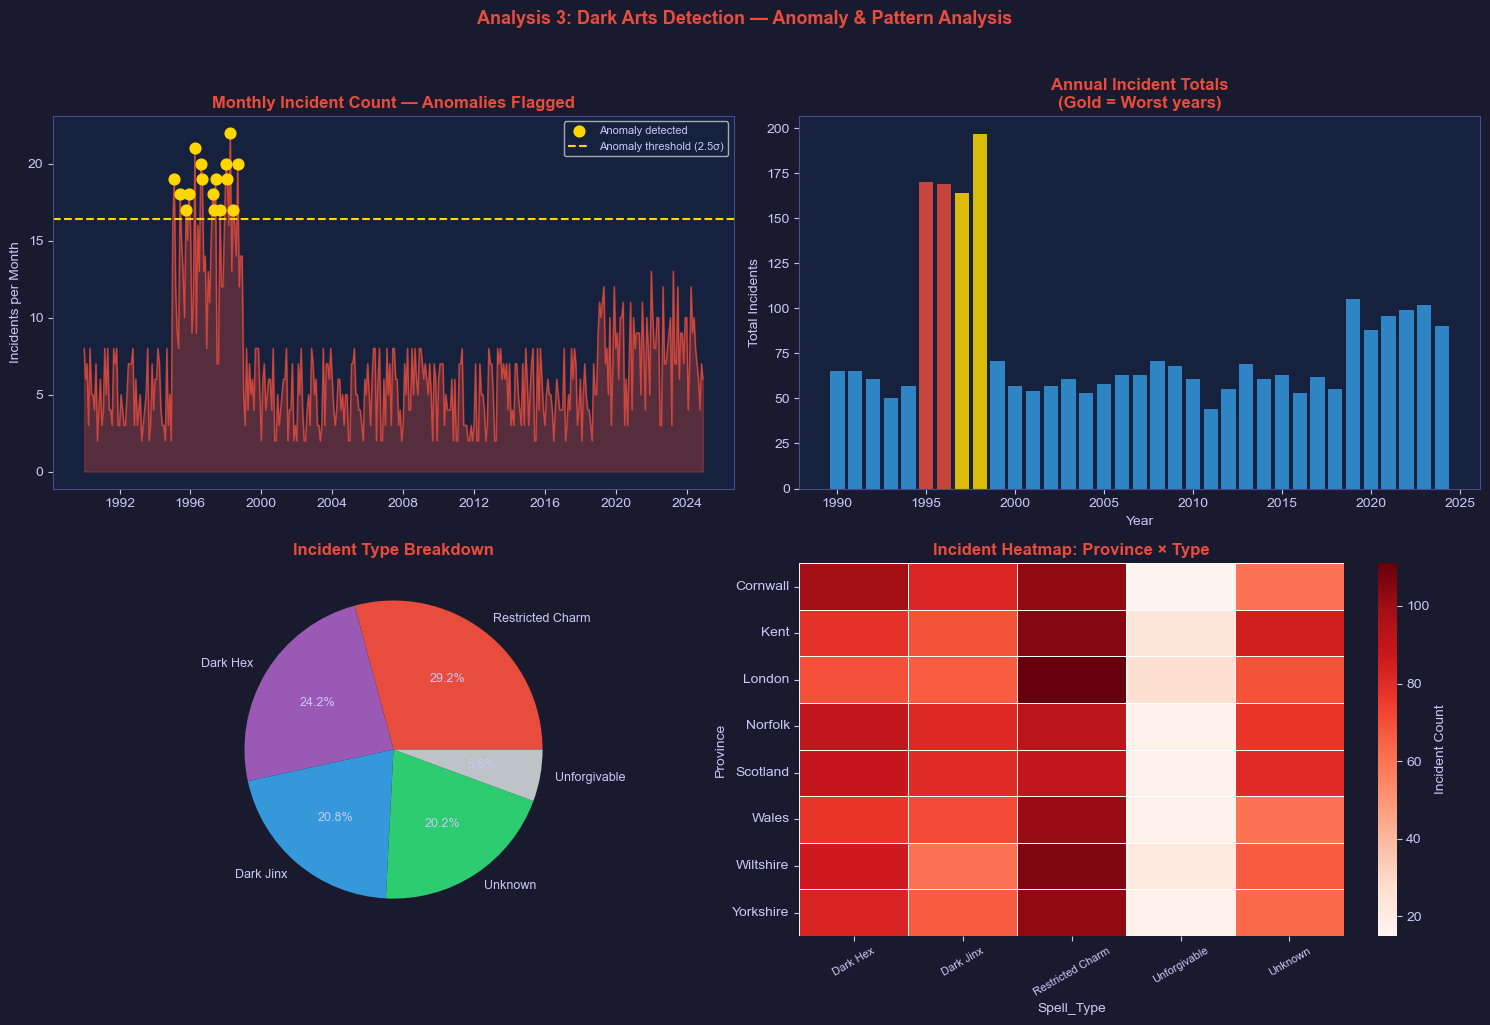


Pembrook's note: The 1995–98 surge is in the annual counts, and every flagged month sits inside it.
The threshold uses the whole archive, so this is a lantern shone backward, not a six-month head start.
I intend to show this to the Auror Office. I have not yet worked up the courage.


In [7]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle('Analysis 3: Dark Arts Detection — Anomaly & Pattern Analysis',
             fontsize=13, fontweight='bold', color=RED, y=1.02)

# Chart 1: Incident time series with anomalies
normal  = monthly[~monthly['Anomaly']]
anomaly = monthly[monthly['Anomaly']]
axes[0,0].fill_between(monthly['Date'], monthly['Total_Incidents'],
                        alpha=0.3, color=RED)
axes[0,0].plot(monthly['Date'], monthly['Total_Incidents'],
               color=RED, linewidth=1, alpha=0.8)
axes[0,0].scatter(anomaly['Date'], anomaly['Total_Incidents'],
                  color=GOLD, s=60, zorder=5, label='Anomaly detected')
axes[0,0].axhline(y=monthly['Total_Incidents'].mean() + 2.5*monthly['Total_Incidents'].std(),
                  color=GOLD, linewidth=1.5, linestyle='--', label='Anomaly threshold (2.5σ)')
axes[0,0].set_title('Monthly Incident Count — Anomalies Flagged', color=RED, fontweight='bold')
axes[0,0].set_ylabel('Incidents per Month')
axes[0,0].legend(fontsize=8)

# Chart 2: Annual trend
annual_incidents = monthly.groupby('Year')['Total_Incidents'].sum()
bar_colors = [GOLD if y in [1997, 1998] else RED if y in [1995,1996] else BLUE
              for y in annual_incidents.index]
axes[0,1].bar(annual_incidents.index, annual_incidents.values,
              color=bar_colors, alpha=0.85)
axes[0,1].set_title('Annual Incident Totals\n(Gold = Worst years)', color=RED, fontweight='bold')
axes[0,1].set_ylabel('Total Incidents')
axes[0,1].set_xlabel('Year')

# Chart 3: Spell type breakdown
spell_counts = incidents_df['Spell_Type'].value_counts()
axes[1,0].pie(spell_counts.values, labels=spell_counts.index,
              colors=[RED, PURPLE, BLUE, GREEN, SILVER],
              autopct='%1.1f%%', textprops={'fontsize': 9})
axes[1,0].set_title('Incident Type Breakdown', color=RED, fontweight='bold')

# Chart 4: Geographic heatmap
geo_pivot = incidents_df.groupby(['Province','Spell_Type']).size().unstack(fill_value=0)
sns.heatmap(geo_pivot, ax=axes[1,1], cmap='Reds', linewidths=0.5,
            cbar_kws={'label': 'Incident Count'})
axes[1,1].set_title('Incident Heatmap: Province × Type', color=RED, fontweight='bold')
axes[1,1].tick_params(axis='x', rotation=30, labelsize=8)

plt.tight_layout()
plt.savefig('chart_03_dark_arts.png', dpi=150, bbox_inches='tight', facecolor='#1a1a2e')
plt.show()
print()
print('Pembrook\'s note: The 1995–98 surge is in the annual counts, and every flagged month sits inside it.')
print('The threshold uses the whole archive, so this is a lantern shone backward, not a six-month head start.')
print('I intend to show this to the Auror Office. I have not yet worked up the courage.')

---
## Analysis 4: Potions Optimization
### *What actually determines whether a potion succeeds?*

Conventional wisdom: follow the instructions exactly, and talent does the rest. Pembrook's hypothesis: temperature, stirring technique, and ingredient quality have measurable, quantifiable effects on success probability — and a classification model can tell us which factors matter most.

In [8]:
# Prepare features
le_dir   = LabelEncoder()
le_moon  = LabelEncoder()
le_qual  = LabelEncoder()
le_lvl   = LabelEncoder()
le_pot   = LabelEncoder()

pot = potions_df.copy()
pot['Stir_Direction_Enc'] = le_dir.fit_transform(pot['Stir_Direction'])
pot['Moon_Phase_Enc']     = le_moon.fit_transform(pot['Moon_Phase'])
pot['Ingredient_Enc']     = le_qual.fit_transform(pot['Ingredient_Quality'])
pot['Brewer_Enc']         = le_lvl.fit_transform(pot['Brewer_Level'])
pot['Potion_Enc']         = le_pot.fit_transform(pot['Potion'])

pot_features = ['Temperature_C', 'Stir_Count', 'Stir_Direction_Enc',
                'Moon_Phase_Enc', 'Ingredient_Enc', 'Brewer_Enc', 'Potion_Enc']

X_pot = pot[pot_features]
y_pot = pot['Success']

X_tr, X_te, y_tr, y_te = train_test_split(X_pot, y_pot, test_size=0.2, random_state=42)

rf_pot = RandomForestClassifier(n_estimators=100, random_state=42)
rf_pot.fit(X_tr, y_tr)
y_pred_pot = rf_pot.predict(X_te)

print('POTIONS SUCCESS PREDICTION MODEL')
print('=' * 50)
print(classification_report(y_te, y_pred_pot,
                              target_names=['Failure', 'Success']))

print('Feature Importance (what actually matters in brewing):')
feat_imp = pd.Series(rf_pot.feature_importances_,
                     index=['Temperature', 'Stir Count', 'Stir Direction',
                            'Moon Phase', 'Ingredient Quality', 'Brewer Level', 'Potion Type']
                    ).sort_values(ascending=False)
for feat, imp in feat_imp.items():
    bar = '█' * int(imp * 40)
    print(f'  {feat:<22} {imp:.3f}  {bar}')

# Success rate by key factors
print()
print('Success rate by brewer level:')
print(potions_df.groupby('Brewer_Level')['Success'].mean().apply(lambda x: f'{x:.1%}').to_string())
print()
print('Success rate by ingredient quality:')
print(potions_df.groupby('Ingredient_Quality')['Success'].mean().apply(lambda x: f'{x:.1%}').to_string())

POTIONS SUCCESS PREDICTION MODEL
              precision    recall  f1-score   support

     Failure       0.58      0.31      0.40        36
     Success       0.69      0.88      0.77        64

    accuracy                           0.67       100
   macro avg       0.64      0.59      0.59       100
weighted avg       0.65      0.67      0.64       100

Feature Importance (what actually matters in brewing):
  Temperature            0.269  ██████████
  Stir Count             0.193  ███████
  Potion Type            0.150  █████
  Brewer Level           0.125  ████
  Ingredient Quality     0.101  ████
  Moon Phase             0.094  ███
  Stir Direction         0.068  ██

Success rate by brewer level:
Brewer_Level
Auror      70.4%
Master     84.6%
NEWT       61.3%
Student    45.9%

Success rate by ingredient quality:
Ingredient_Quality
Exceptional    79.2%
Good           66.5%
Poor           50.9%
Standard       57.6%


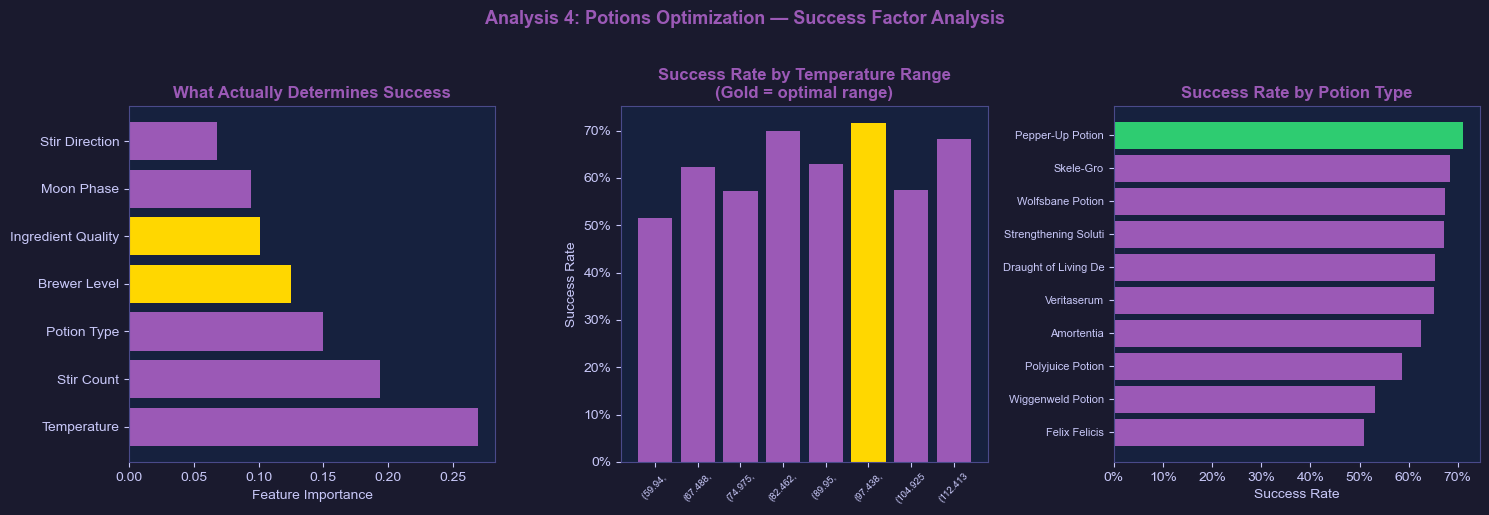


Pembrook's note: Temperature and stir count lead the splits. Skill and ingredients are fourth and fifth.
The averages still favor Masters. Snape may have the averages. The forest keeps the ranking.


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle('Analysis 4: Potions Optimization — Success Factor Analysis',
             fontsize=13, fontweight='bold', color=PURPLE, y=1.02)

# Chart 1: Feature importance
feat_colors = [GOLD if f in ['Brewer Level', 'Ingredient Quality'] else PURPLE
               for f in feat_imp.index]
axes[0].barh(feat_imp.index, feat_imp.values, color=feat_colors)
axes[0].set_title('What Actually Determines Success', color=PURPLE, fontweight='bold')
axes[0].set_xlabel('Feature Importance')

# Chart 2: Success by temperature
temp_bins = pd.cut(potions_df['Temperature_C'], bins=8)
temp_success = potions_df.groupby(temp_bins)['Success'].mean()
axes[1].bar(range(len(temp_success)), temp_success.values,
            color=[GOLD if v == temp_success.max() else PURPLE for v in temp_success.values])
axes[1].set_title('Success Rate by Temperature Range\n(Gold = optimal range)', color=PURPLE, fontweight='bold')
axes[1].set_ylabel('Success Rate')
axes[1].set_xticks(range(len(temp_success)))
axes[1].set_xticklabels([str(x)[:8] for x in temp_success.index], rotation=45, fontsize=7)
axes[1].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{x:.0%}'))

# Chart 3: Success by potion type
potion_success = potions_df.groupby('Potion')['Success'].mean().sort_values()
axes[2].barh(range(len(potion_success)), potion_success.values,
             color=[GREEN if v > 0.7 else RED if v < 0.4 else PURPLE
                    for v in potion_success.values])
axes[2].set_yticks(range(len(potion_success)))
axes[2].set_yticklabels([p[:20] for p in potion_success.index], fontsize=8)
axes[2].set_title('Success Rate by Potion Type', color=PURPLE, fontweight='bold')
axes[2].set_xlabel('Success Rate')
axes[2].xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{x:.0%}'))

plt.tight_layout()
plt.savefig('chart_04_potions.png', dpi=150, bbox_inches='tight', facecolor='#1a1a2e')
plt.show()
print()
print('Pembrook\'s note: Temperature and stir count lead the splits. Skill and ingredients are fourth and fifth.')
print('The averages still favor Masters. Snape may have the averages. The forest keeps the ranking.')

---
## Analysis 5: Alchemy — Transmutation Modeling
### *Is the Philosopher's Stone really necessary, or is it just the most famous shortcut?*

Grand Master alchemists have long insisted that only a Philosopher's Stone enables reliable gold transmutation. Pembrook's analysis examines whether temperature, timing, lunar alignment, and alchemist skill level can substitute for — or at least significantly close the gap with — stone-assisted transmutation.

In [10]:
# Logistic regression on alchemy success
alch = alchemy_df.copy()
le_stone = LabelEncoder()
le_moon2 = LabelEncoder()
le_lvl2  = LabelEncoder()
le_base  = LabelEncoder()
le_tgt   = LabelEncoder()

alch['Stone_Enc']  = le_stone.fit_transform(alch['Philosophers_Stone'])
alch['Moon_Enc']   = le_moon2.fit_transform(alch['Moon_Phase'])
alch['Level_Enc']  = le_lvl2.fit_transform(alch['Alchemist_Level'])
alch['Base_Enc']   = le_base.fit_transform(alch['Base_Metal'])
alch['Target_Enc'] = le_tgt.fit_transform(alch['Target_Metal'])

alch_features = ['Temperature_C', 'Time_Hours', 'Stone_Enc',
                 'Moon_Enc', 'Level_Enc', 'Base_Enc', 'Target_Enc']

X_a = alch[alch_features]
y_a = alch['Success']

X_tr_a, X_te_a, y_tr_a, y_te_a = train_test_split(X_a, y_a, test_size=0.2, random_state=42)

scaler_a = StandardScaler()
X_tr_sc  = scaler_a.fit_transform(X_tr_a)
X_te_sc  = scaler_a.transform(X_te_a)

lr = LogisticRegression(random_state=42, max_iter=1000)
lr.fit(X_tr_sc, y_tr_a)

print('ALCHEMY TRANSMUTATION — LOGISTIC REGRESSION')
print('=' * 50)
print(classification_report(y_te_a, lr.predict(X_te_sc),
                              target_names=['Failure', 'Success']))

# Success rates by stone and level
print('Success rates by Philosopher\'s Stone availability:')
stone_rates = alch.groupby('Philosophers_Stone')['Success'].agg(['mean','count'])
stone_rates.columns = ['Success Rate', 'N Attempts']
stone_rates['Success Rate'] = stone_rates['Success Rate'].apply(lambda x: f'{x:.1%}')
print(stone_rates.to_string())
print()
print('Success rates by alchemist level (no stone):')
level_order = ['Apprentice', 'Journeyman', 'Adept', 'Grand Master']
no_stone = alch[alch['Philosophers_Stone'] == 'None']
no_stone_tbl = no_stone.groupby('Alchemist_Level')['Success'].agg(['mean', 'count'])
no_stone_tbl = no_stone_tbl.reindex(level_order)
no_stone_tbl.columns = ['Success Rate', 'N Attempts']
no_stone_tbl['Success Rate'] = no_stone_tbl['Success Rate'].apply(lambda x: f'{x:.1%}')
print(no_stone_tbl.to_string())

ALCHEMY TRANSMUTATION — LOGISTIC REGRESSION
              precision    recall  f1-score   support

     Failure       0.82      1.00      0.90        49
     Success       0.00      0.00      0.00        11

    accuracy                           0.82        60
   macro avg       0.41      0.50      0.45        60
weighted avg       0.67      0.82      0.73        60

Success rates by Philosopher's Stone availability:
                   Success Rate  N Attempts
Philosophers_Stone                         
Genuine                   75.0%          16
None                      17.9%         201
Partial                   24.1%          54
Replica                   24.1%          29

Success rates by alchemist level (no stone):
                Success Rate  N Attempts
Alchemist_Level                         
Apprentice              3.2%          63
Journeyman             17.4%          69
Adept                  14.3%          42
Grand Master           59.3%          27


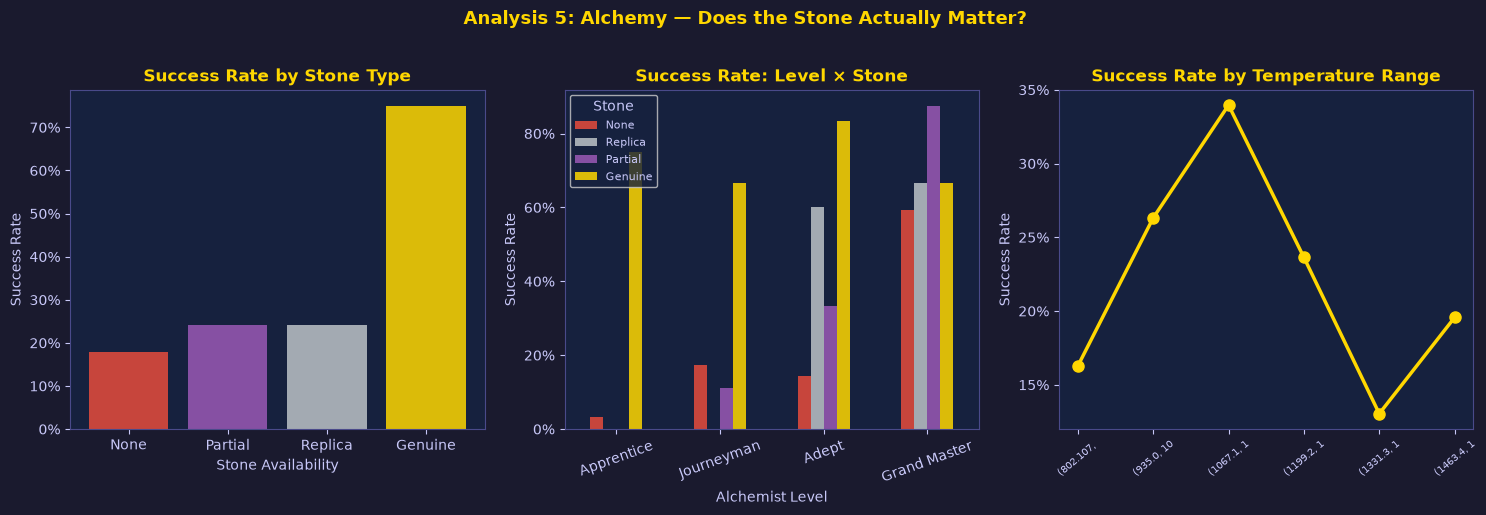


Grand Masters with no stone: 59.3% (n=27)
Apprentices with a genuine stone: 75.0% (n=4)
Pembrook's note: With 'None' kept as a category, the Grand Master without a stone
does not outpace the Apprentice who holds a genuine one. That apprentice cell is
4 attempts. Skill still climbs with rank. Bring sample sizes to the symposium.


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle('Analysis 5: Alchemy — Does the Stone Actually Matter?',
             fontsize=13, fontweight='bold', color=GOLD, y=1.02)

# Chart 1: Success rate by stone type
stone_color = {'None': RED, 'Replica': SILVER, 'Partial': PURPLE, 'Genuine': GOLD}
stone_success = alchemy_df.groupby('Philosophers_Stone')['Success'].mean().sort_values()
axes[0].bar(stone_success.index, stone_success.values,
            color=[stone_color.get(s, BLUE) for s in stone_success.index], alpha=0.85)
axes[0].set_title('Success Rate by Stone Type', color=GOLD, fontweight='bold')
axes[0].set_ylabel('Success Rate')
axes[0].set_xlabel('Stone Availability')
axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{x:.0%}'))

# Chart 2: Level × Stone interaction
level_stone = alchemy_df.groupby(['Alchemist_Level', 'Philosophers_Stone'])['Success'].mean().unstack()
level_order = ['Apprentice', 'Journeyman', 'Adept', 'Grand Master']
stone_cols = [c for c in ['None', 'Replica', 'Partial', 'Genuine'] if c in level_stone.columns]
level_stone = level_stone.reindex(level_order)[stone_cols]
level_stone.plot(kind='bar', ax=axes[1],
                 color=[stone_color[c] for c in stone_cols], alpha=0.85)
axes[1].set_title('Success Rate: Level × Stone', color=GOLD, fontweight='bold')
axes[1].set_ylabel('Success Rate')
axes[1].set_xlabel('Alchemist Level')
axes[1].set_xticklabels(level_order, rotation=20)
axes[1].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{x:.0%}'))
axes[1].legend(title='Stone', fontsize=8)

# Chart 3: Temperature vs success rate
temp_bins_a = pd.cut(alchemy_df['Temperature_C'], bins=6)
temp_succ_a = alchemy_df.groupby(temp_bins_a)['Success'].mean()
axes[2].plot(range(len(temp_succ_a)), temp_succ_a.values,
             marker='o', color=GOLD, linewidth=2.5, markersize=8)
axes[2].set_title('Success Rate by Temperature Range', color=GOLD, fontweight='bold')
axes[2].set_ylabel('Success Rate')
axes[2].set_xticks(range(len(temp_succ_a)))
axes[2].set_xticklabels([str(x)[:10] for x in temp_succ_a.index], rotation=40, fontsize=7)
axes[2].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{x:.0%}'))

plt.tight_layout()
plt.savefig('chart_05_alchemy.png', dpi=150, bbox_inches='tight', facecolor='#1a1a2e')
plt.show()
print()
gm_none = alchemy_df[(alchemy_df['Alchemist_Level'] == 'Grand Master') &
                     (alchemy_df['Philosophers_Stone'] == 'None')]
ap_gen = alchemy_df[(alchemy_df['Alchemist_Level'] == 'Apprentice') &
                    (alchemy_df['Philosophers_Stone'] == 'Genuine')]
print(f"Grand Masters with no stone: {gm_none['Success'].mean():.1%} (n={len(gm_none)})")
print(f"Apprentices with a genuine stone: {ap_gen['Success'].mean():.1%} (n={len(ap_gen)})")
print("Pembrook's note: With 'None' kept as a category, the Grand Master without a stone")
print("does not outpace the Apprentice who holds a genuine one. That apprentice cell is")
print(f"{len(ap_gen)} attempts. Skill still climbs with rank. Bring sample sizes to the symposium.")

---
## Conclusions & Risk Assessment

### What the Data Tells Us

| Analysis | Finding | Muggle Method | Score |
|---|---|---|---|
| Lost Charms | Syllable count leads the splits (0.338). Holdout R² is −0.244, worse than predicting the mean. 30 lost charms score ≥70; that list is the model's opinion. | Random Forest Regression | R² = −0.244 |
| Herbology | k=4 was set in the code, then named by average potency. Across 30 plants, potency and toxicity correlate at about −0.02. | K-Means Clustering | k=4, chosen |
| Dark Arts | 16 months exceed 2.5σ, all of them inside 1995–1998. The threshold uses the whole archive. 2024 (90 incidents) sits with 2019–2023. | Z-score on monthly counts | 16 months |
| Potions | Temperature (0.269) and stir count (0.193) lead. Brewer level plus ingredient quality is about 0.23. Holdout accuracy is 67%. | Random Forest Classification | 67% accuracy |
| Alchemy | 'None' stays a category: 201 attempts, 17.9% success. Grand Masters with no stone succeed 59.3% (n=27). Apprentices with a genuine stone succeed 75% (n=4). The refit predicts every test failure and none of the 11 successes. | Logistic Regression | 82% accuracy |

### On the Question of Discovery

I am aware that what I am doing would be considered — by the Ministry's Standards of Practice for Enchanted Records Management — somewhere between 'irregular' and 'potentially grounds for disciplinary review.'

I would like to note, for the record, that the Ministry of Magic has been managing these questions by committee for four hundred years and the Auror Office still responds to anomalies based on owl-post tips from concerned citizens.

My wand has not combusted in five years.

I consider this progress.

— *R. Pembrook*  
*Accio evidence of wrongdoing — Finite Incantatem*